In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression, RFECV
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
import shap


In [2]:
import os
from pathlib import Path
import pandas as pd

# Get the project root directory
project_root = Path(os.getcwd()).parent
config_path = project_root / "configs"

from electricity_forecast.config_and_logging import load_config_hydra
config = load_config_hydra("config_cv.yaml", config_path=config_path)

train_df = pd.read_csv(project_root / "data" / "data_raw" / "df_train.csv")
test_df = pd.read_csv(project_root / "data" / "data_raw" / "df_test.csv")

In [3]:
def create_lag_features(df, target_column, max_days=7):
    """
    Create lag features for renewable energy forecasting (3-hour periods)
    - Daily lags: 1-8 (same day pattern)  
    - Weekly lags: 8, 16, 24, 32, 40, 48, 56 (daily intervals for a week)
    """
    df_lagged = df.copy()
    
    # Daily pattern lags (1-8 periods = 3-24 hours)
    daily_lags = list(range(1, 9))  # 1, 2, 3, ..., 8
    
    # Weekly pattern lags (every 8th period for 7 days)
    weekly_lags = [8 * day for day in range(1, max_days + 1)]  # 8, 16, 24, 32, 40, 48, 56
    
    # Combine and remove duplicates
    all_lags = sorted(list(set(daily_lags + weekly_lags)))
    
    # Create lag features and track lag column names
    lag_columns = []
    for lag in all_lags:
        lag_col_name = f'{target_column}_lag_{lag}'
        df_lagged[lag_col_name] = df_lagged[target_column].shift(lag)
        lag_columns.append(lag_col_name)
    
    # Only drop rows that have NaN in ANY of the lag columns
    # This preserves rows where other variables might have NaN but lags are valid
    df_lagged = df_lagged.dropna(subset=lag_columns)
    
    print(f"Created {len(lag_columns)} lag features: {lag_columns}")
    
    return df_lagged, lag_columns

# Apply lag creation BEFORE pipeline
feature_names_no_lags = train_df.columns
train_df_with_lags, created_lags = create_lag_features(train_df, config['data']['target_column'])
train_df = train_df_with_lags.copy()

Created 14 lag features: ['load_shortfall_3h_lag_1', 'load_shortfall_3h_lag_2', 'load_shortfall_3h_lag_3', 'load_shortfall_3h_lag_4', 'load_shortfall_3h_lag_5', 'load_shortfall_3h_lag_6', 'load_shortfall_3h_lag_7', 'load_shortfall_3h_lag_8', 'load_shortfall_3h_lag_16', 'load_shortfall_3h_lag_24', 'load_shortfall_3h_lag_32', 'load_shortfall_3h_lag_40', 'load_shortfall_3h_lag_48', 'load_shortfall_3h_lag_56']


In [4]:

train_df.head(5)

,Unnamed: 0,time,Madrid_wind_speed,Valencia_wind_deg,Bilbao_rain_1h,Valencia_wind_speed,Seville_humidity,Madrid_humidity,Bilbao_clouds_all,Bilbao_wind_speed,...,load_shortfall_3h_lag_5,load_shortfall_3h_lag_6,load_shortfall_3h_lag_7,load_shortfall_3h_lag_8,load_shortfall_3h_lag_16,load_shortfall_3h_lag_24,load_shortfall_3h_lag_32,load_shortfall_3h_lag_40,load_shortfall_3h_lag_48,load_shortfall_3h_lag_56
56,56,2015-01-08 09:00:00,1.0,level_10,0.0,2.000000,93.000000,70.000000,18.666667,1.0,...,14671.000000,14613.666667,16370.666667,13965.666667,14337.000000,6379.666667,2710.000000,623.000000,-1850.333333,6715.666667
57,57,2015-01-08 12:00:00,1.0,level_7,0.0,1.000000,85.666667,70.666667,49.000000,1.0,...,15614.000000,14671.000000,14613.666667,16370.666667,15028.333333,7973.666667,1281.333333,-2679.333333,-4002.333333,4171.666667
58,58,2015-01-08 15:00:00,1.0,level_6,0.0,2.000000,77.666667,66.000000,68.000000,1.0,...,15496.666667,15614.000000,14671.000000,14613.666667,14496.000000,1129.333333,5200.000000,-1478.000000,-2893.000000,4274.666667
59,59,2015-01-08 18:00:00,1.0,level_7,0.0,2.666667,84.000000,76.333333,71.333333,1.0,...,9562.000000,15496.666667,15614.000000,14671.000000,13313.666667,3238.333333,5179.333333,2212.666667,539.333333,5075.666667
60,60,2015-01-08 21:00:00,1.0,level_7,0.0,3.333333,90.666667,67.666667,56.666667,1.0,...,7215.666667,9562.000000,15496.666667,15614.000000,14642.333333,5385.000000,4187.333333,145.000000,65.000000,6620.666667


In [5]:

from electricity_forecast.preprocessing import get_pipeline_for_model
# Configure your pipeline to maintain DataFrame output

# Force scaling to be true
config['models'][1]['scaling'] = True
pipeline = get_pipeline_for_model(config['models'][1], config)
y = train_df[config['data']['target_column']]

# Fit the pipeline on training data
train_processed = pipeline.fit_transform(train_df)
train_processed = pd.DataFrame(train_processed)
y.index = train_processed.index

# Transform both training and test data
target_column = config['data']['target_column']

In [6]:
feature_names_no_lags

Index(['Unnamed: 0', 'time', 'Madrid_wind_speed', 'Valencia_wind_deg',
       'Bilbao_rain_1h', 'Valencia_wind_speed', 'Seville_humidity',
       'Madrid_humidity', 'Bilbao_clouds_all', 'Bilbao_wind_speed',
       'Seville_clouds_all', 'Bilbao_wind_deg', 'Barcelona_wind_speed',
       'Barcelona_wind_deg', 'Madrid_clouds_all', 'Seville_wind_speed',
       'Barcelona_rain_1h', 'Seville_pressure', 'Seville_rain_1h',
       'Bilbao_snow_3h', 'Barcelona_pressure', 'Seville_rain_3h',
       'Madrid_rain_1h', 'Barcelona_rain_3h', 'Valencia_snow_3h',
       'Madrid_weather_id', 'Barcelona_weather_id', 'Bilbao_pressure',
       'Seville_weather_id', 'Valencia_pressure', 'Seville_temp_max',
       'Madrid_pressure', 'Valencia_temp_max', 'Valencia_temp',
       'Bilbao_weather_id', 'Seville_temp', 'Valencia_humidity',
       'Valencia_temp_min', 'Barcelona_temp_max', 'Madrid_temp_max',
       'Barcelona_temp', 'Bilbao_temp_min', 'Bilbao_temp',
       'Barcelona_temp_min', 'Bilbao_temp_max', 'Sev

In [7]:
feature_names_transformed = pipeline.named_steps['preprocessor'].get_feature_names_out(feature_names_no_lags)
len(feature_names_transformed)

53

In [8]:
feature_names_transformed

array(['Seville_temp_max', 'Bilbao_wind_speed', 'Seville_rain_3h',
       'Madrid_temp', 'Barcelona_temp', 'Madrid_rain_1h',
       'Madrid_temp_min', 'Bilbao_clouds_all', 'Valencia_wind_deg',
       'Barcelona_weather_id', 'Madrid_pressure', 'Madrid_humidity',
       'Bilbao_pressure', 'Seville_temp_min', 'Madrid_wind_speed',
       'Bilbao_rain_1h', 'Seville_temp', 'Seville_weather_id',
       'Bilbao_weather_id', 'Seville_clouds_all', 'Barcelona_rain_1h',
       'Bilbao_wind_deg', 'Barcelona_pressure', 'Barcelona_wind_deg',
       'Bilbao_temp_min', 'Seville_humidity', 'Barcelona_wind_speed',
       'Valencia_snow_3h', 'Madrid_temp_max', 'Bilbao_temp_max',
       'Seville_pressure', 'Barcelona_temp_max', 'Seville_wind_speed',
       'Valencia_humidity', 'Valencia_temp_min', 'Seville_rain_1h',
       'Bilbao_snow_3h', 'Valencia_temp', 'Madrid_weather_id',
       'Madrid_clouds_all', 'Barcelona_rain_3h', 'Barcelona_temp_min',
       'Valencia_pressure', 'Valencia_temp_max', 'Valencia_

In [9]:
feature_names_transformed = feature_names_transformed.tolist()
feature_names_with_lags = feature_names_transformed + created_lags
train_processed.columns = feature_names_with_lags
len(feature_names_with_lags)

67

In [10]:
train_processed.head()

,Seville_temp_max,Bilbao_wind_speed,Seville_rain_3h,Madrid_temp,Barcelona_temp,Madrid_rain_1h,Madrid_temp_min,Bilbao_clouds_all,Valencia_wind_deg,Barcelona_weather_id,...,load_shortfall_3h_lag_5,load_shortfall_3h_lag_6,load_shortfall_3h_lag_7,load_shortfall_3h_lag_8,load_shortfall_3h_lag_16,load_shortfall_3h_lag_24,load_shortfall_3h_lag_32,load_shortfall_3h_lag_40,load_shortfall_3h_lag_48,load_shortfall_3h_lag_56
0,-0.774802,1.649365,-0.362891,-0.246310,1.347381,0.518906,-0.766918,-0.504551,-0.56491,0.466070,...,-1.944147,-2.415766,-0.768633,1.000057e+00,-0.999780,0.61583,-1.272612,0.718904,1.235762,-1.236107
1,-0.774802,0.605813,-0.362891,-0.660210,1.023185,0.546240,0.165138,-0.504551,-0.56491,0.485624,...,-2.580113,-2.829577,-1.257836,9.399773e-17,-1.413970,0.61583,-1.272612,0.718904,1.235762,-1.236107
2,-0.774802,0.257962,-0.362891,-0.246310,0.669517,0.354903,0.748953,-0.504551,-0.56491,0.443256,...,-2.348759,-2.616262,-1.238030,-1.000057e+00,-0.999780,0.61583,-1.272612,0.718904,1.235762,-1.236107
3,-0.774802,0.605813,-0.362891,0.029623,0.949504,0.778579,0.851377,-0.504551,-0.56491,0.430220,...,-1.638007,-1.956254,-1.084000,-1.414295e+00,0.000162,0.61583,-1.272612,0.718904,1.235762,-1.236107
4,-0.774802,0.605813,-0.362891,0.305556,1.244228,0.423237,0.400713,-0.504551,-0.56491,0.384593,...,-2.036201,-2.047465,-0.786901,-1.000057e+00,1.000105,0.61583,-1.272612,0.718904,1.235762,-1.236107


In [11]:
X = train_processed.copy()
print(X.index.equals(y.index))
print(len(X), len(y))


True
8707 8707


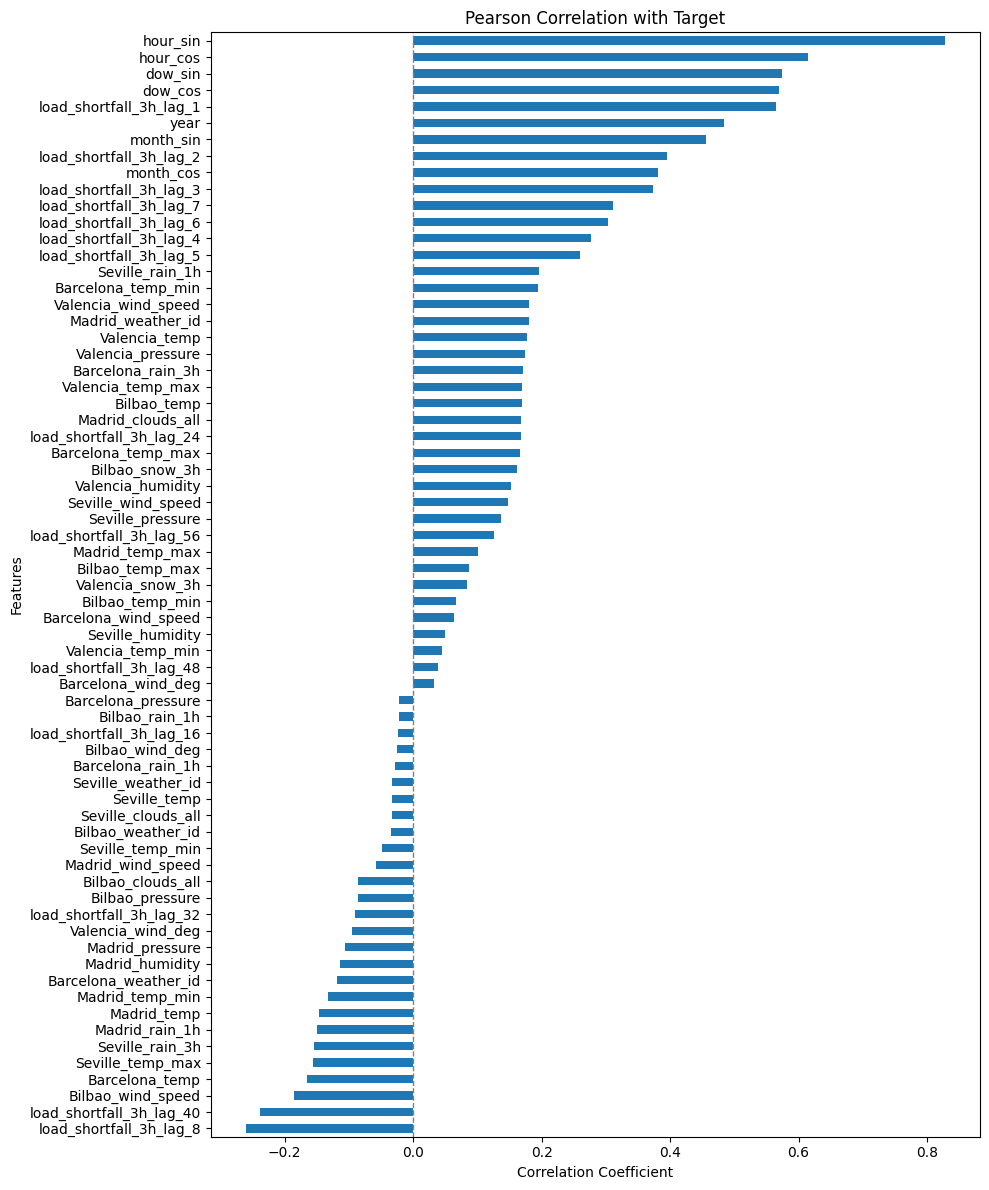

In [12]:
corrs = X.corrwith(y).sort_values()

plt.figure(figsize=(10, 12))
corrs.plot(kind='barh', title='Pearson Correlation with Target')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.axvline(0, color='grey', lw=1, ls='--')
plt.tight_layout()
plt.show()

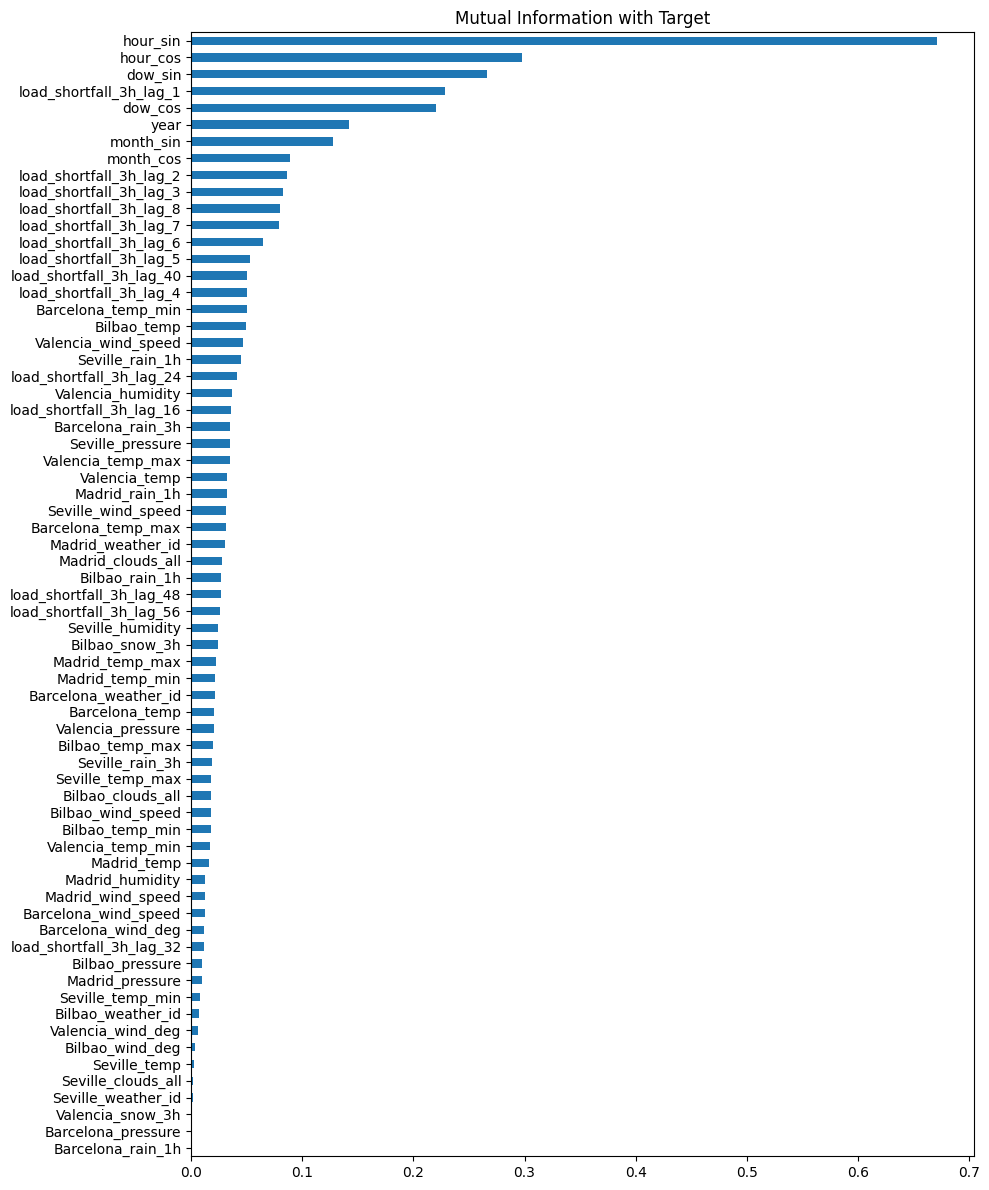

In [13]:
mi_scores = mutual_info_regression(X, y, random_state=0)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values()

plt.figure(figsize=(10, 12))
mi_series.plot(kind='barh', title='Mutual Information with Target')
plt.tight_layout()
plt.show()

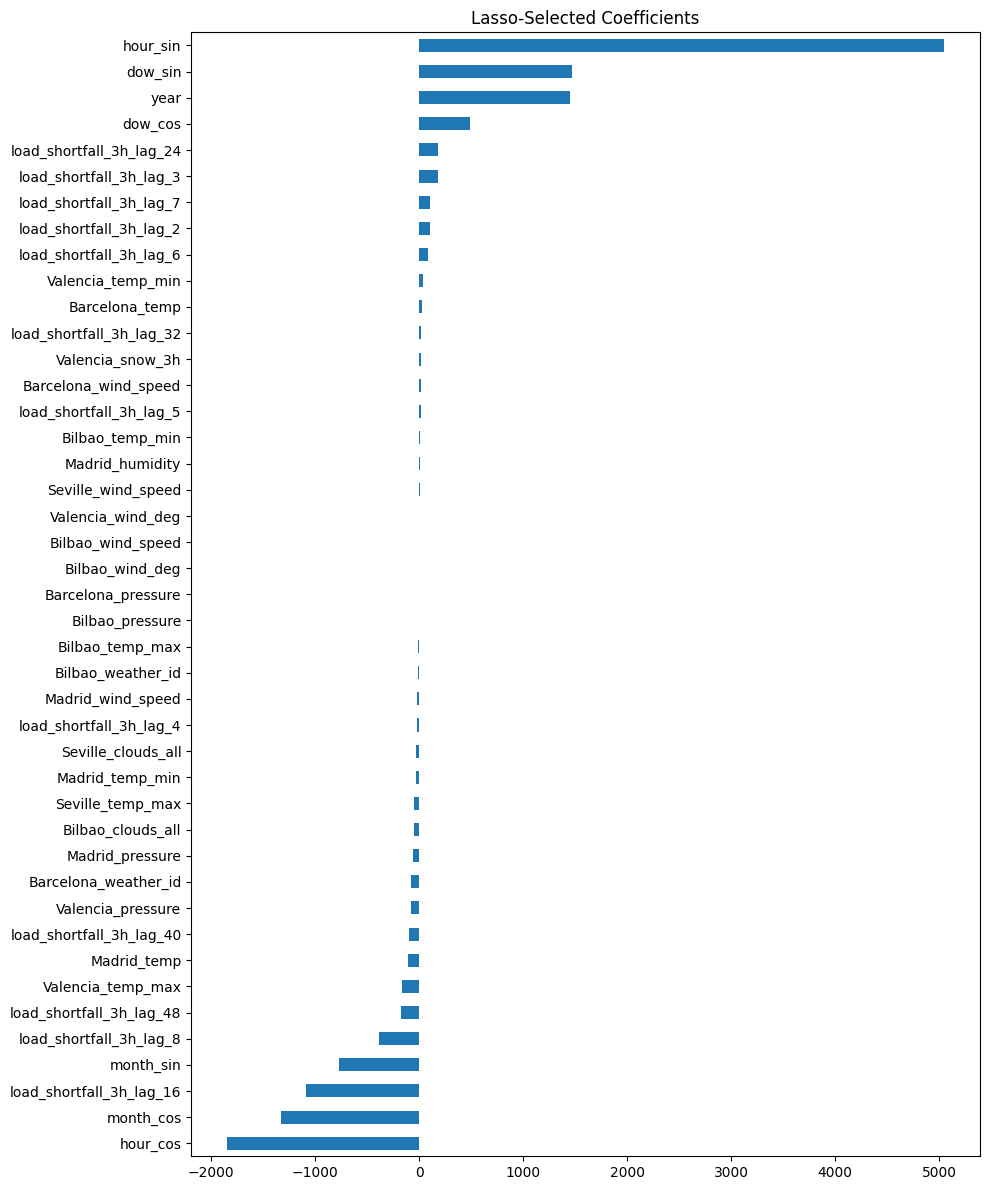

In [14]:
pipe = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=10000))
pipe.fit(X, y)

lasso = pipe.named_steps['lassocv']
lasso_coefs = pd.Series(lasso.coef_, index=X.columns)
lasso_selected = lasso_coefs[lasso_coefs != 0].sort_values()

plt.figure(figsize=(10, 12))
lasso_selected.plot(kind='barh', title='Lasso-Selected Coefficients')
plt.tight_layout()
plt.show()

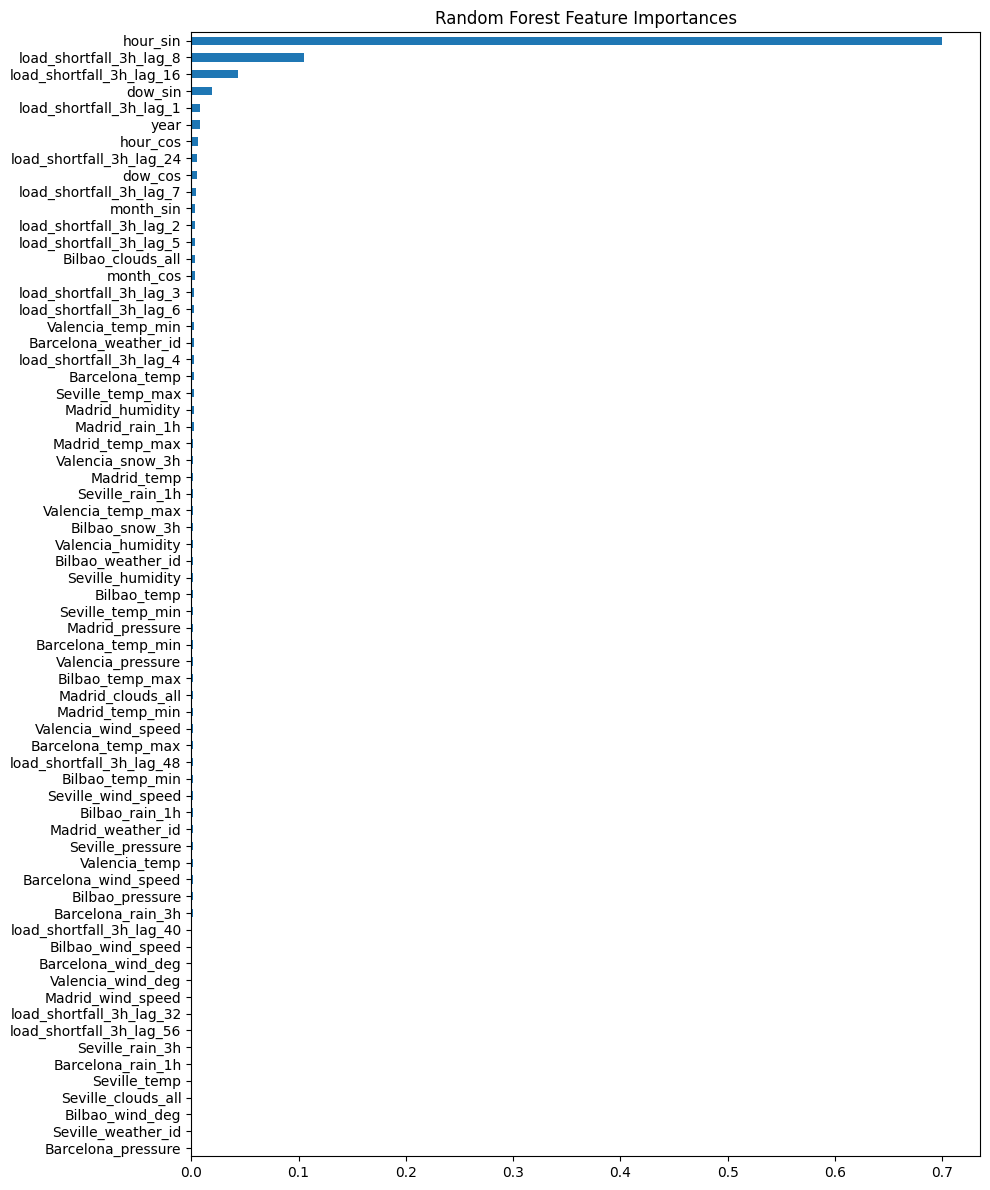

In [15]:
rf = RandomForestRegressor(n_estimators=100, random_state=0)
rf.fit(X, y)

rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(10, 12))
rf_importance.plot(kind='barh', title='Random Forest Feature Importances')
plt.tight_layout()
plt.show()

In [18]:
explainer = shap.Explainer(rf, X)
shap_values = explainer(X)

shap.plots.bar(shap_values, max_display=30)

100%|===================| 8696/8707 [09:25<00:00]        

ExplainerError: Additivity check failed in TreeExplainer! Please ensure the data matrix you passed to the explainer is the same shape that the model was trained on. If your data shape is correct then please report this on GitHub. This check failed because for one of the samples the sum of the SHAP values was 11184.542972, while the model output was 11078.856667. If this difference is acceptable you can set check_additivity=False to disable this check.

In [17]:
from xgboost import XGBRegressor 
rfe = RFECV(estimator=XGBRegressor(),
              step=1, 
              cv=TimeSeriesSplit(n_splits=5),
              scoring='neg_mean_squared_error') 
X_selected_scaled = rfe.fit_transform(train_processed, y)
X_selected_scaled

array([[-0.50455144, -0.69634855, -0.20361458, ...,  0.71890354,
         1.23576153, -1.23610676],
       [-0.50455144, -0.31666949, -0.20361458, ...,  0.71890354,
         1.23576153, -1.23610676],
       [-0.50455144, -0.03191019, -0.20361458, ...,  0.71890354,
         1.23576153, -1.23610676],
       ...,
       [ 3.81205625,  2.329219  , -0.20361458, ...,  0.01160696,
         1.42520401,  1.21890728],
       [ 0.47649576,  1.32069648, -0.20361458, ...,  0.01160696,
         1.42520401,  1.21890728],
       [-0.11213256, -0.69634855, -0.20361458, ...,  0.01160696,
         1.42520401,  1.21890728]])

In [19]:
X_selected_scaled.shape

(8707, 36)

In [20]:
rfe.feature_names_in_

array(['Seville_temp_max', 'Bilbao_wind_speed', 'Seville_rain_3h',
       'Madrid_temp', 'Barcelona_temp', 'Madrid_rain_1h',
       'Madrid_temp_min', 'Bilbao_clouds_all', 'Valencia_wind_deg',
       'Barcelona_weather_id', 'Madrid_pressure', 'Madrid_humidity',
       'Bilbao_pressure', 'Seville_temp_min', 'Madrid_wind_speed',
       'Bilbao_rain_1h', 'Seville_temp', 'Seville_weather_id',
       'Bilbao_weather_id', 'Seville_clouds_all', 'Barcelona_rain_1h',
       'Bilbao_wind_deg', 'Barcelona_pressure', 'Barcelona_wind_deg',
       'Bilbao_temp_min', 'Seville_humidity', 'Barcelona_wind_speed',
       'Valencia_snow_3h', 'Madrid_temp_max', 'Bilbao_temp_max',
       'Seville_pressure', 'Barcelona_temp_max', 'Seville_wind_speed',
       'Valencia_humidity', 'Valencia_temp_min', 'Seville_rain_1h',
       'Bilbao_snow_3h', 'Valencia_temp', 'Madrid_weather_id',
       'Madrid_clouds_all', 'Barcelona_rain_3h', 'Barcelona_temp_min',
       'Valencia_pressure', 'Valencia_temp_max', 'Valencia_

In [40]:
rfe.ranking_

array([29, 31, 27, 26, 25, 23, 22,  1, 21, 20, 19, 16,  1, 17,  1, 15, 30,
       24, 10, 11, 28, 18, 32,  6,  7,  5, 13, 14,  3,  9,  2,  8, 12,  1,
        1,  1,  1,  4,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [46]:
selected_features

['Bilbao_clouds_all',
 'Bilbao_pressure',
 'Madrid_wind_speed',
 'Valencia_humidity',
 'Valencia_temp_min',
 'Seville_rain_1h',
 'Bilbao_snow_3h',
 'Madrid_weather_id',
 'Madrid_clouds_all',
 'Barcelona_rain_3h',
 'Barcelona_temp_min',
 'Valencia_pressure',
 'Valencia_temp_max',
 'Valencia_wind_speed',
 'Bilbao_temp',
 'hour_sin',
 'hour_cos',
 'dow_sin',
 'dow_cos',
 'month_sin',
 'month_cos',
 'year',
 'load_shortfall_3h_lag_1',
 'load_shortfall_3h_lag_2',
 'load_shortfall_3h_lag_3',
 'load_shortfall_3h_lag_4',
 'load_shortfall_3h_lag_5',
 'load_shortfall_3h_lag_6',
 'load_shortfall_3h_lag_7',
 'load_shortfall_3h_lag_8',
 'load_shortfall_3h_lag_16',
 'load_shortfall_3h_lag_24',
 'load_shortfall_3h_lag_32',
 'load_shortfall_3h_lag_40',
 'load_shortfall_3h_lag_48',
 'load_shortfall_3h_lag_56']

In [67]:
selected = pd.DataFrame(rfe.ranking_ == 1)
selected.index = pd.Series(rfe.feature_names_in_)
selected.columns = ["RFE CV selected"]
selected.head(50)

,RFE CV selected
Seville_temp_max,False
Bilbao_wind_speed,False
Seville_rain_3h,False
Madrid_temp,False
Barcelona_temp,False
Madrid_rain_1h,False
Madrid_temp_min,False
Bilbao_clouds_all,True
Valencia_wind_deg,False
Barcelona_weather_id,False


In [53]:
len(rfe.feature_names_in_)

67

In [56]:
selected[(~selected[0].isin(set(selected_features))) & selected['selected']].count()

0           0
selected    0
dtype: int64

In [25]:
selected_features = [feature for i, feature in enumerate(rfe.feature_names_in_) if rfe.ranking_[i]==1]
selected_features

['Bilbao_clouds_all',
 'Bilbao_pressure',
 'Madrid_wind_speed',
 'Valencia_humidity',
 'Valencia_temp_min',
 'Seville_rain_1h',
 'Bilbao_snow_3h',
 'Madrid_weather_id',
 'Madrid_clouds_all',
 'Barcelona_rain_3h',
 'Barcelona_temp_min',
 'Valencia_pressure',
 'Valencia_temp_max',
 'Valencia_wind_speed',
 'Bilbao_temp',
 'hour_sin',
 'hour_cos',
 'dow_sin',
 'dow_cos',
 'month_sin',
 'month_cos',
 'year',
 'load_shortfall_3h_lag_1',
 'load_shortfall_3h_lag_2',
 'load_shortfall_3h_lag_3',
 'load_shortfall_3h_lag_4',
 'load_shortfall_3h_lag_5',
 'load_shortfall_3h_lag_6',
 'load_shortfall_3h_lag_7',
 'load_shortfall_3h_lag_8',
 'load_shortfall_3h_lag_16',
 'load_shortfall_3h_lag_24',
 'load_shortfall_3h_lag_32',
 'load_shortfall_3h_lag_40',
 'load_shortfall_3h_lag_48',
 'load_shortfall_3h_lag_56']

In [68]:
summary = pd.DataFrame({
    'Correlation': corrs,
    'Mutual_Info': mi_series,
    'Lasso_Coeff': lasso_coefs,
    'RF_Importance': rf_importance
}).fillna(0)

summary = summary.merge(selected, left_index=True, right_index=True, how='left')

summary['Combined_Score'] = (
    summary['Mutual_Info'].rank() +
    summary['RF_Importance'].rank() +
    summary['Lasso_Coeff'].abs().rank()
)

summary.sort_values('Combined_Score', ascending=False).head(50)

,Correlation,Mutual_Info,Lasso_Coeff,RF_Importance,RFE CV selected,Combined_Score
hour_sin,0.827978,0.670982,5048.782946,0.700035,True,201.0
dow_sin,0.574910,0.266160,1469.942111,0.019427,True,194.0
hour_cos,0.614959,0.297656,-1845.368785,0.006056,True,193.0
year,0.484217,0.141944,1453.537860,0.007944,True,188.0
dow_cos,0.569343,0.220740,488.882320,0.005038,True,182.0
load_shortfall_3h_lag_8,-0.260447,0.080285,-382.616971,0.104881,True,182.0
month_sin,0.456448,0.127864,-771.603565,0.003746,True,179.0
month_cos,0.381881,0.088578,-1322.623940,0.003158,True,176.0
load_shortfall_3h_lag_16,-0.023592,0.035870,-1082.737991,0.043607,True,172.0
load_shortfall_3h_lag_7,0.311688,0.078645,109.905929,0.004242,True,168.0


ADF Statistic: -23.13260908784198
p-value: 0.0
Critical Values: {'1%': np.float64(-3.43110464208646), '5%': np.float64(-2.8618735012686005), '10%': np.float64(-2.5669475177740573)}


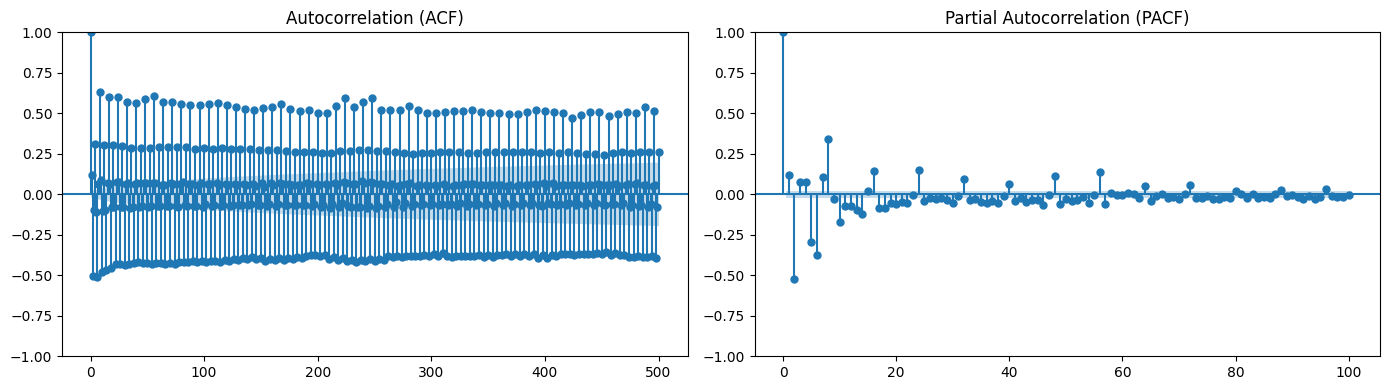

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

diff_series = train_df[target_column].diff().dropna()

from statsmodels.tsa.stattools import adfuller
result = adfuller(diff_series)
print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:', result[4])
# Plot ACF and PACF side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(diff_series, lags=500, ax=axes[0])
axes[0].set_title("Autocorrelation (ACF)")

plot_pacf(diff_series, lags=100, ax=axes[1], method='ywm')
axes[1].set_title("Partial Autocorrelation (PACF)")

plt.tight_layout()
plt.show()

# Time dummies
* Cyclical dummies added

c:\Users\lackerman008\OneDrive - pwc\Outside\Code\Machine learning\Electricity Shortfall Challenge\preprocessing.py:400: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  


            hour_block  hour_sin  hour_cos  day_of_week   dow_sin  dow_cos  \
2015-01-05           0       0.0       1.0            0  0.000000  1.00000   
2015-02-02           0       0.0       1.0            0  0.000000  1.00000   
2015-03-02           0       0.0       1.0            0  0.000000  1.00000   
2015-04-06           0       0.0       1.0            0  0.000000  1.00000   
2015-05-04           0       0.0       1.0            0  0.000000  1.00000   
2015-06-01           0       0.0       1.0            0  0.000000  1.00000   
2015-07-06           0       0.0       1.0            0  0.000000  1.00000   
2015-08-03           0       0.0       1.0            0  0.000000  1.00000   
2015-09-07           0       0.0       1.0            0  0.000000  1.00000   
2015-10-05           0       0.0       1.0            0  0.000000  1.00000   
2015-11-02           0       0.0       1.0            0  0.000000  1.00000   
2015-12-07           0       0.0       1.0            0  0.00000

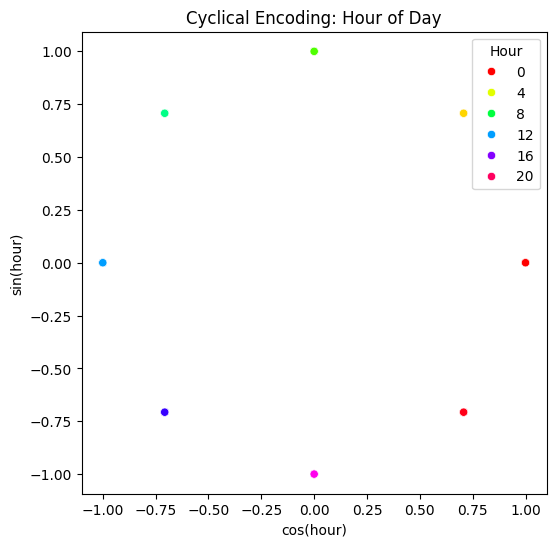

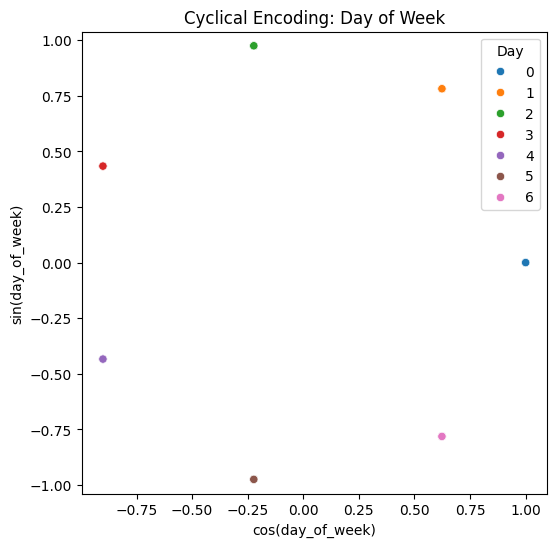

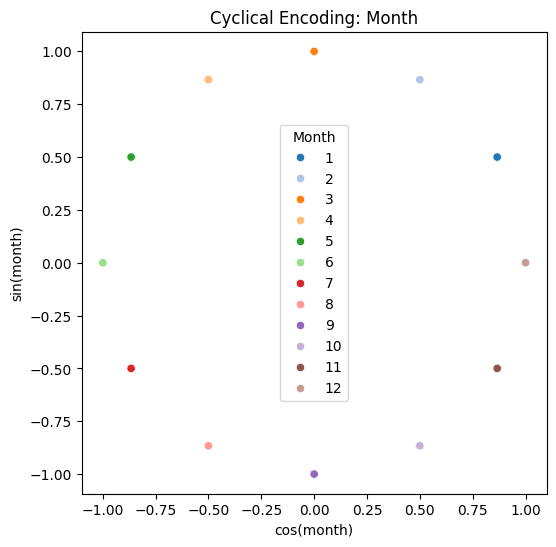

In [ ]:
import numpy as np
from data_loading import load_data
from preprocessing import set_datetime_as_index

train_df, test_df, sample_submission = load_data(config)
target_column = config['data']['target_column']
df = train_df.copy()
df = set_datetime_as_index(df)
timestamp_col = 'time'

df['hour_block'] = df.index.hour       # For 3-hour intervals: values will be 0, 3, 6, ..., 21
df['day_of_week'] = df.index.dayofweek # 0 = Monday
df['month'] = df.index.month      

df['hour_sin'] = np.sin(2 * np.pi * df['hour_block'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour_block'] / 24)

df['dow_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['dow_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)

df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Show unique combinations
display_columns = ['hour_block', 'hour_sin', 'hour_cos',
                   'day_of_week', 'dow_sin', 'dow_cos',
                   'month', 'month_sin', 'month_cos']

# Drop duplicates to show unique encodings
df_display = df[display_columns].drop_duplicates().sort_values(['hour_block', 'day_of_week', 'month'])
print(df_display.head(20))


import matplotlib.pyplot as plt
import seaborn as sns

# Visualize Hour of Day
plt.figure(figsize=(6, 6))
sns.scatterplot(data=df_display, x='hour_cos', y='hour_sin', hue='hour_block', palette='hsv')
plt.title("Cyclical Encoding: Hour of Day")
plt.xlabel("cos(hour)")
plt.ylabel("sin(hour)")
plt.axis('equal')
plt.legend(title="Hour")
plt.show()

# Visualize Day of Week
plt.figure(figsize=(6, 6))
sns.scatterplot(data=df_display, x='dow_cos', y='dow_sin', hue='day_of_week', palette='tab10')
plt.title("Cyclical Encoding: Day of Week")
plt.xlabel("cos(day_of_week)")
plt.ylabel("sin(day_of_week)")
plt.axis('equal')
plt.legend(title="Day")
plt.show()

# Visualize Month
plt.figure(figsize=(6, 6))
sns.scatterplot(data=df_display, x='month_cos', y='month_sin', hue='month', palette='tab20')
plt.title("Cyclical Encoding: Month")
plt.xlabel("cos(month)")
plt.ylabel("sin(month)")
plt.axis('equal')
plt.legend(title="Month")
plt.show()